In [6]:
# Panji Malik Ibrahim_202431202

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request

# Baca dataset dan tampilkan datanya
df = pd.read_csv('heart.csv')
print("=== DATA PERTAMA (head) ===")
print(df.head())

# Lihat informasi data dan deskripsi statistik
print("\n=== INFORMASI DATASET (info) ===")
df.info()

print("\n=== DESKRIPSI STATISTIK (describe) ===")
print(df.describe())

=== DATA PERTAMA (head) ===
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

=== INFORMASI DATASET (info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  10

In [7]:
# Panji Malik Ibrahim_202431202

# Pisahkan fitur numerik dan tampilkan jumlah serta daftarnya
fitur_numerik = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("=== FITUR NUMERIK ===")
print(f"Jumlah fitur numerik : {len(fitur_numerik)}")
print(f"Daftar fitur numerik  : {fitur_numerik}\n")

# Pisahkan fitur kategorikal dan tampilkan jumlah serta daftarnya
fitur_kategorikal = df.select_dtypes(include=['object']).columns.tolist()
print("=== FITUR KATEGORIKAL ===")
print(f"Jumlah fitur kategorikal : {len(fitur_kategorikal)}")
print(f"Daftar fitur kategorikal  : {fitur_kategorikal}\n")

# Tampilkan isi unik tiap fitur kategorikal
print("=== LANGKAH 6: ISI UNIK FITUR KATEGORIKAL ===")
if len(fitur_kategorikal) > 0:
    for col in fitur_kategorikal:
        print(f"Isi unik kolom '{col}':")
        print(df[col].unique())
        print("-" * 40)
else:
    print("Tidak ada fitur berjenis tipe data objek/string (semua kolom berbentuk angka/numerik).")

=== FITUR NUMERIK ===
Jumlah fitur numerik : 14
Daftar fitur numerik  : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

=== FITUR KATEGORIKAL ===
Jumlah fitur kategorikal : 0
Daftar fitur kategorikal  : []

=== LANGKAH 6: ISI UNIK FITUR KATEGORIKAL ===
Tidak ada fitur berjenis tipe data objek/string (semua kolom berbentuk angka/numerik).


In [8]:
# Panji Malik Ibrahim_202431202
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Ubah fitur kategorikal menjadi angka dengan LabelEncoder
df_encoded = df.copy()
le = LabelEncoder()

for col in fitur_kategorikal:
    df_encoded[col] = le.fit_transform(df_encoded[col])

print("=== DATA PERTAMA SETELAH ENCODING ===")
print(df_encoded.head())

# pisahkan fitur X dan target y
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

print("\n=== PEMISAHAN FITUR X DAN TARGET Y ===")
print(f"Bentuk/Ukuran X : {X.shape}")
print(f"Bentuk/Ukuran y : {y.shape}")

# Bagi data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

print("\n=== PEMBAGIAN DATA LATIH & UJI ===")
print(f"Jumlah Data Latih (X_train) : {len(X_train)} baris")
print(f"Jumlah Data Uji (X_test)   : {len(X_test)} baris")

=== DATA PERTAMA SETELAH ENCODING ===
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

=== PEMISAHAN FITUR X DAN TARGET Y ===
Bentuk/Ukuran X : (1025, 13)
Bentuk/Ukuran y : (1025,)

=== PEMBAGIAN DATA LATIH & UJI ===
Jumlah Data Latih (X_train) : 768 baris
Jumlah Data Uji (X_test)   : 257 baris


=== EVALUASI DATA TRAINING ===

Confusion Matrix - Training:
[[294  82]
 [ 61 331]]

Classification Report - Training:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       376
           1       0.80      0.84      0.82       392

    accuracy                           0.81       768
   macro avg       0.81      0.81      0.81       768
weighted avg       0.81      0.81      0.81       768



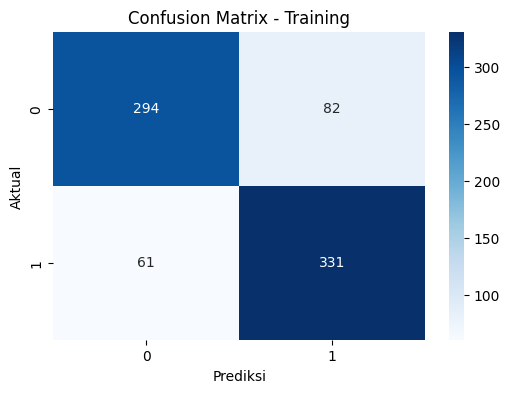


=== EVALUASI DATA TESTING ===

Confusion Matrix - Testing:
[[ 98  25]
 [ 15 119]]

Classification Report - Testing:
              precision    recall  f1-score   support

           0       0.87      0.80      0.83       123
           1       0.83      0.89      0.86       134

    accuracy                           0.84       257
   macro avg       0.85      0.84      0.84       257
weighted avg       0.85      0.84      0.84       257



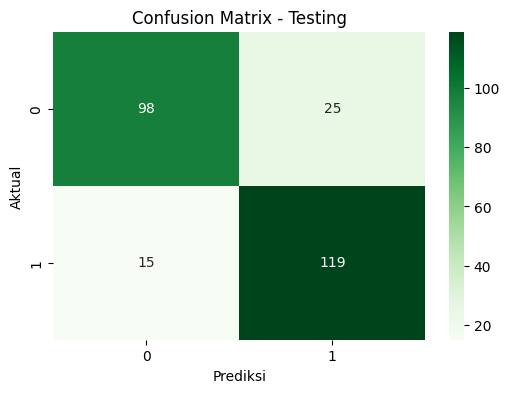

In [9]:
# Panji Malik Ibrahim_202431202
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

# Buat model GaussianNB() dan latih (fit)
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

# Prediksi data latih dan data uji (predict)
y_pred_train = model_nb.predict(X_train)
y_pred_test = model_nb.predict(X_test)

# Evaluasi data latih
print("=== EVALUASI DATA TRAINING ===")
print("\nConfusion Matrix - Training:")
cm_train = confusion_matrix(y_train, y_pred_train)
print(cm_train)

print("\nClassification Report - Training:")
print(classification_report(y_train, y_pred_train))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Training")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

# Evaluasi data uji
print("\n=== EVALUASI DATA TESTING ===")
print("\nConfusion Matrix - Testing:")
cm_test = confusion_matrix(y_test, y_pred_test)
print(cm_test)

print("\nClassification Report - Testing:")
print(classification_report(y_test, y_pred_test))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Testing")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

In [10]:
# Panji Malik Ibrahim_202431202

# Uji dengan 1 data baru
data_baru = pd.DataFrame([{
    'age': 55,
    'sex': 1,
    'cp': 2,
    'trestbps': 130,
    'chol': 250,
    'fbs': 0,
    'restecg': 1,
    'thalach': 150,
    'exang': 0,
    'oldpeak': 1.5,
    'slope': 1,
    'ca': 0,
    'thal': 2
}])

# Melakukan prediksi dengan model GaussianNB
prediksi_kode = model_nb.predict(data_baru)

# Mapping kode angka hasil prediksi ke keterangan teks
label_map = {0: 'Tidak Ada Penyakit Jantung', 1: 'Ada Indikasi Penyakit Jantung'}
hasil_prediksi_label = label_map[prediksi_kode[0]]

print("=== HASIL PREDIKSI 1 DATA BARU ===")
print("Data Baru yang Diuji:")
print(data_baru)
print(f"\nHasil Prediksi Target: {hasil_prediksi_label} (Kode: {prediksi_kode[0]})")

=== HASIL PREDIKSI 1 DATA BARU ===
Data Baru yang Diuji:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   55    1   2       130   250    0        1      150      0      1.5      1   

   ca  thal  
0   0     2  

Hasil Prediksi Target: Ada Indikasi Penyakit Jantung (Kode: 1)
